# Solar filament instance segmentation: the whole pipeline, from the test images to the submission

Team **Hibiki8739**, Solar Filament Segmentation Challenge 2026. This notebook reproduces the final submission from the
competition's test images and the trained weights in `weights/`, **without retraining anything**. The outputs shown below
are those of the Kaggle run (`filament-solfil-inference`, 2 x T4 GPUs) whose `submission.csv` is the selected final submission.

Steps (`solfil.pipeline.run`; stage numbers refer to `training/`):
1. preprocessing: image / disk median, limb-flattened image, 1024 px copies;
2. networks (5 fold models each): dense maps B, C, D (stages 02-04), simulated annotators E (05), Mask R-CNN detectors at
   1024 px and 2048 px (12, 13);
3. stage 14: calibrated ensemble map -> about 157 candidates per image -> descriptors -> first LightGBM quality model ->
   greedy pixel-disjoint selection;
4. stage 15: oriented crops of the selected instances -> three refiner networks (stages 09-11);
5. stage 16: descriptors of the refined outlines -> second LightGBM -> final pixel-disjoint instances.

Set `SOLFIL_TEST_IMAGES` to the folder of the test images (`MAGFiLO_1.0_Kaggle_2026/test/test_images`) and install
`requirements.txt`. At the end: the out-of-fold evaluation of the same pipeline on the training images (stage 16).


In [ ]:
import os, sys, json, glob, pickle, shutil
import numpy as np, pandas as pd
sys.path.insert(0, os.path.abspath('.'))     # the package solfil/ of this repository
WD = 'weights'                                # trained weights (float16) and LightGBM models
IMAGES = os.environ.get('SOLFIL_TEST_IMAGES', 'MAGFiLO_1.0_Kaggle_2026/test/test_images')   # the competition's test images

## Weights: collected from the training notebooks, stored in float16 in the repository layout

In [ ]:
# On Kaggle this cell collected the weights from the training notebooks (tools/export_weights_kaggle.py);
# here they are read from weights/.
sizes = {d: round(sum(os.path.getsize(os.path.join(r, x)) for r, _, fs in os.walk(f'{WD}/{d}') for x in fs) / 2 ** 20, 1) for d in sorted(os.listdir(WD))}
print('weights (MB)', sizes, 'total', round(sum(sizes.values()), 1), 'largest file (MB)',
      round(max(os.path.getsize(os.path.join(r, x)) for r, _, fs in os.walk(WD) for x in fs) / 2 ** 20, 1), flush=True)
print(json.load(open(f'{WD}/stage1/model.json'))['variant'], json.load(open(f'{WD}/stage2/model.json')), flush=True)

weights (MB) {'dense_b_effb4': 195.0, 'dense_c_r34_2048': 233.5, 'dense_d_unetpp_spine': 249.3, 'detector_1024': 438.7, 'detector_2048': 438.7, 'refiner_unet_effb4': 195.1, 'refiner_unet_resnext50': 306.3, 'refiner_unetpp_r34': 249.4, 'sim_annotators': 233.9, 'stage1': 5.2, 'stage2': 1.7} total 2546.8 largest file (MB) 87.7
BCD_d23_avg {'score': 'all_mid', 'features': ['src', 'src_score', 't', 'close', 'group', 'fine', 'larea', 'w', 'h', 'pmax', 'pmean', 'pmed', 'p10', 'p90', 'frac5', 'frac7', 'pring', 'smean', 's90', 'imean', 'ring', 'contrast', 'imin', 'solidity', 'compact', 'elong', 'width', 'rdisk', 'hole_frac', 'frag_n', 'frag_max', 'core', 'spmax', 'spmean', 'sp_len', 'sp_n', 'sp_main', 'sp_ring', 'img_n', 'img_larea', 'rel_area', 'img_spread', 'n_inside', 'n_cont', 'area_ratio_up', 'sim_q', 'sim_m', 'sim_iou', 'sim_iou_sd', 'sim_cov', 'sim_any', 'sim_nt', 'sim_over', 'sim_q_team', 'sim_m_team', 'sim_q_solo', 'sim_iou_max', 'sim_iou_q25', 'sim_q_lo', 'sim_m_lo', 'sim_q_hi', 'sim_

## Inference

In [ ]:
from solfil.pipeline import run
sub = run(IMAGES, WD, '/tmp/solfil', 'submission.csv', workers=4)

19:18:12 prepared 180 images
19:19:12 gpu0: 
19:19:12 gpu1: 
19:20:12 gpu0: 
19:20:12 gpu1: 
19:21:12 gpu0: 
19:21:12 gpu1: 
19:22:12 gpu0: 
19:22:12 gpu1: 
19:23:12 gpu0: 
19:23:12 gpu1: 
19:24:12 gpu0: 
19:24:12 gpu1: 
19:25:12 gpu0: 
19:25:12 gpu1: 
19:26:12 gpu0: 
19:26:12 gpu1: 
19:27:12 gpu0: 
19:27:12 gpu1: 
19:28:12 gpu0: 
19:28:12 gpu1: 
19:29:12 gpu0: 
19:29:12 gpu1: 
19:30:12 gpu0: 
19:30:12 gpu1: 
19:31:12 gpu0: 
19:31:12 gpu1: 
19:32:12 gpu0: 
19:32:12 gpu1: 
19:33:12 gpu0: 
19:33:12 gpu1: 
19:34:12 gpu0: 
19:34:12 gpu1: 
19:35:12 gpu0: 
19:35:12 gpu1: 
19:36:12 gpu0: 
19:36:12 gpu1: 
19:37:12 gpu0: 
19:37:12 gpu1: 
19:38:12 gpu0: 19:37:28 network C done 1151s
19:38:12 gpu1: 
19:39:12 gpu0: 19:37:28 network C done 1151s
19:39:12 gpu1: 
19:40:12 gpu0: 19:37:28 network C done 1151s
19:40:12 gpu1: 
19:41:12 gpu0: 19:37:28 network C done 1151s
19:41:12 gpu1: 
19:42:12 gpu0: 19:42:08 network B done 280s
19:42:12 gpu1: 
19:43:12 gpu0: 19:42:08 network B done 280s
19:43:12 gpu1: 

## Figures: one test image through the pipeline, final instances on test images, stage-2 refinement

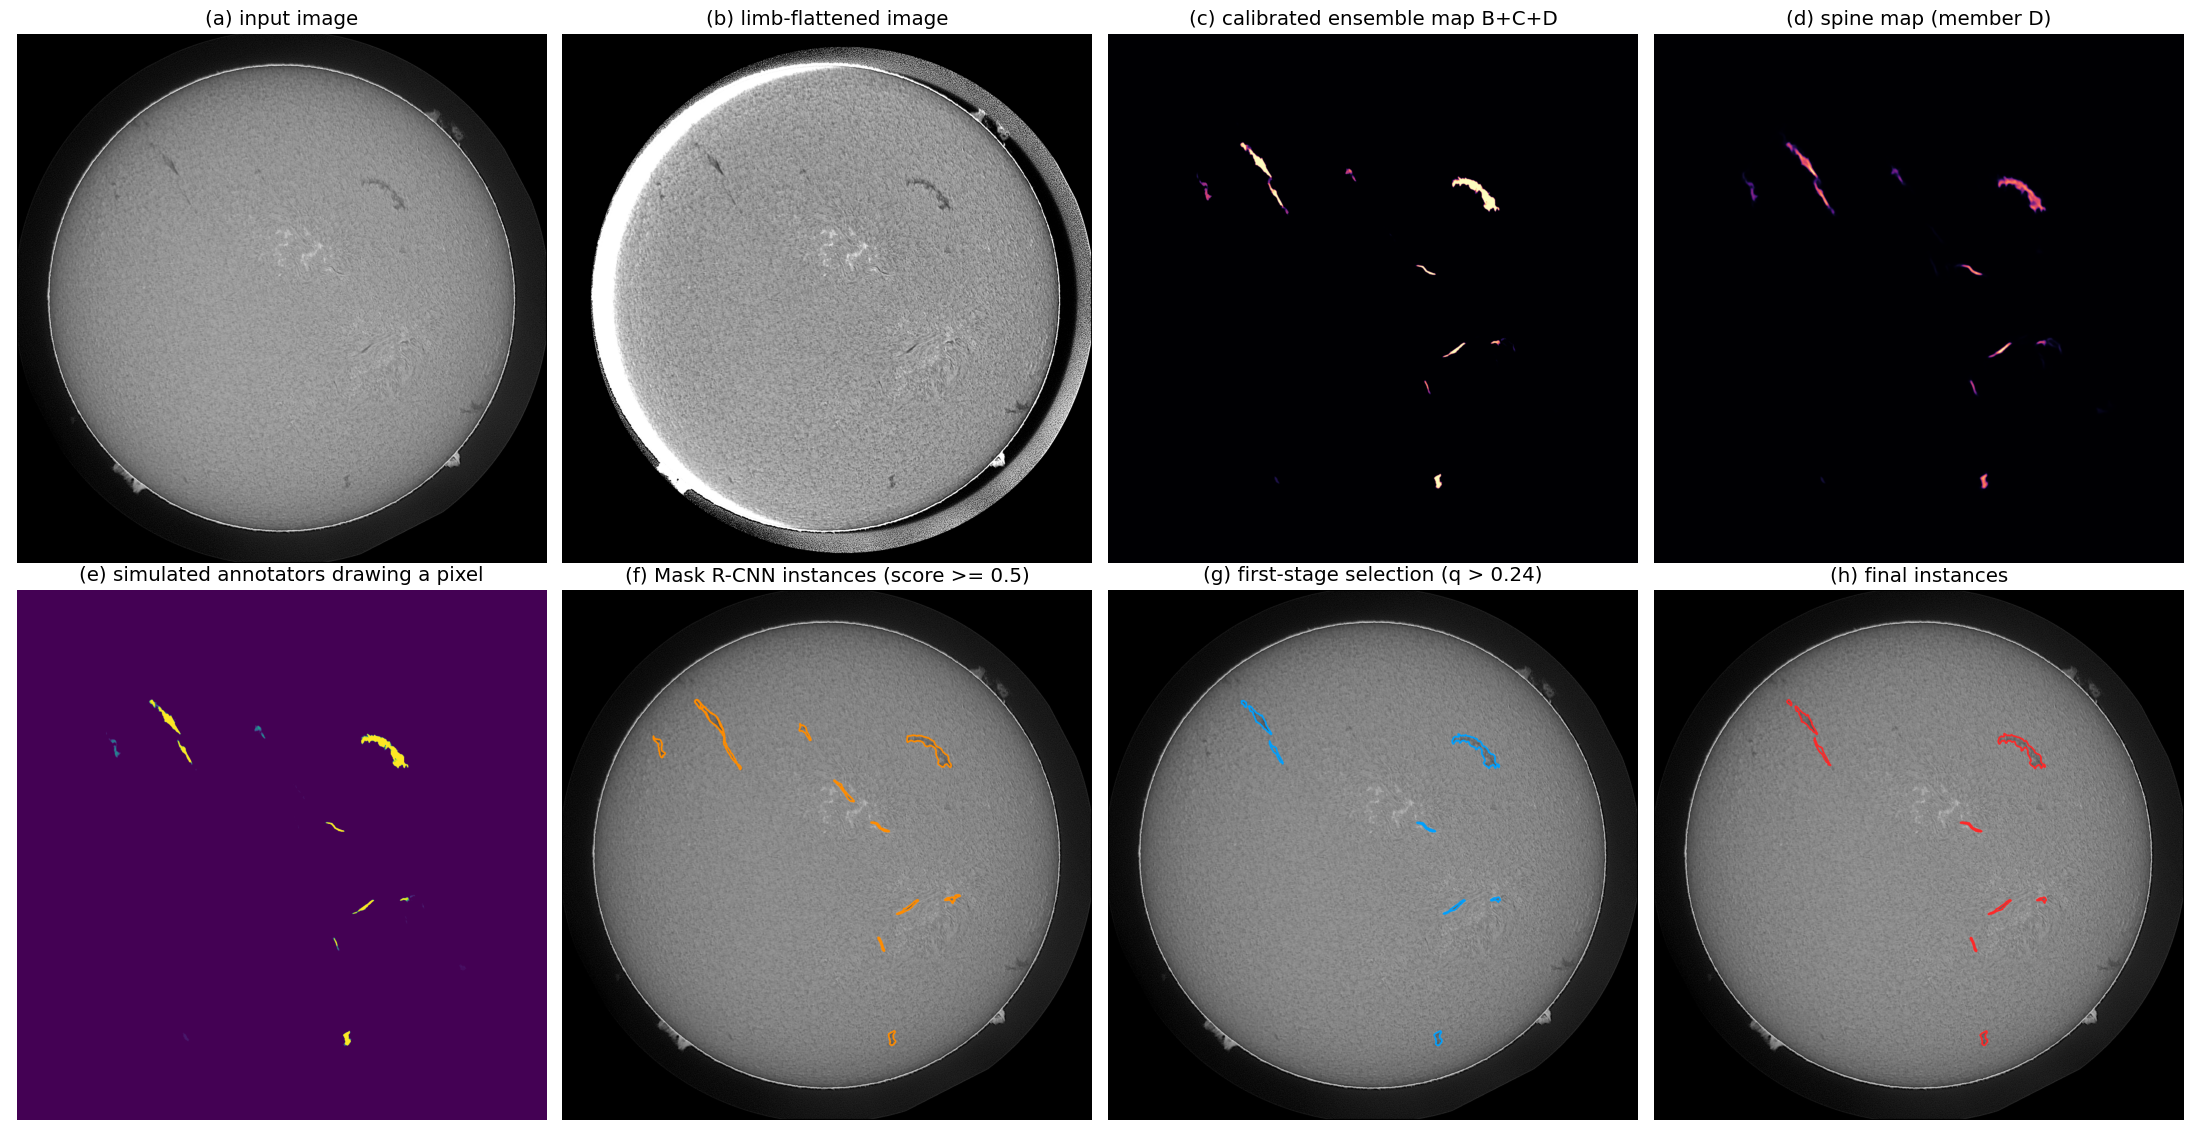

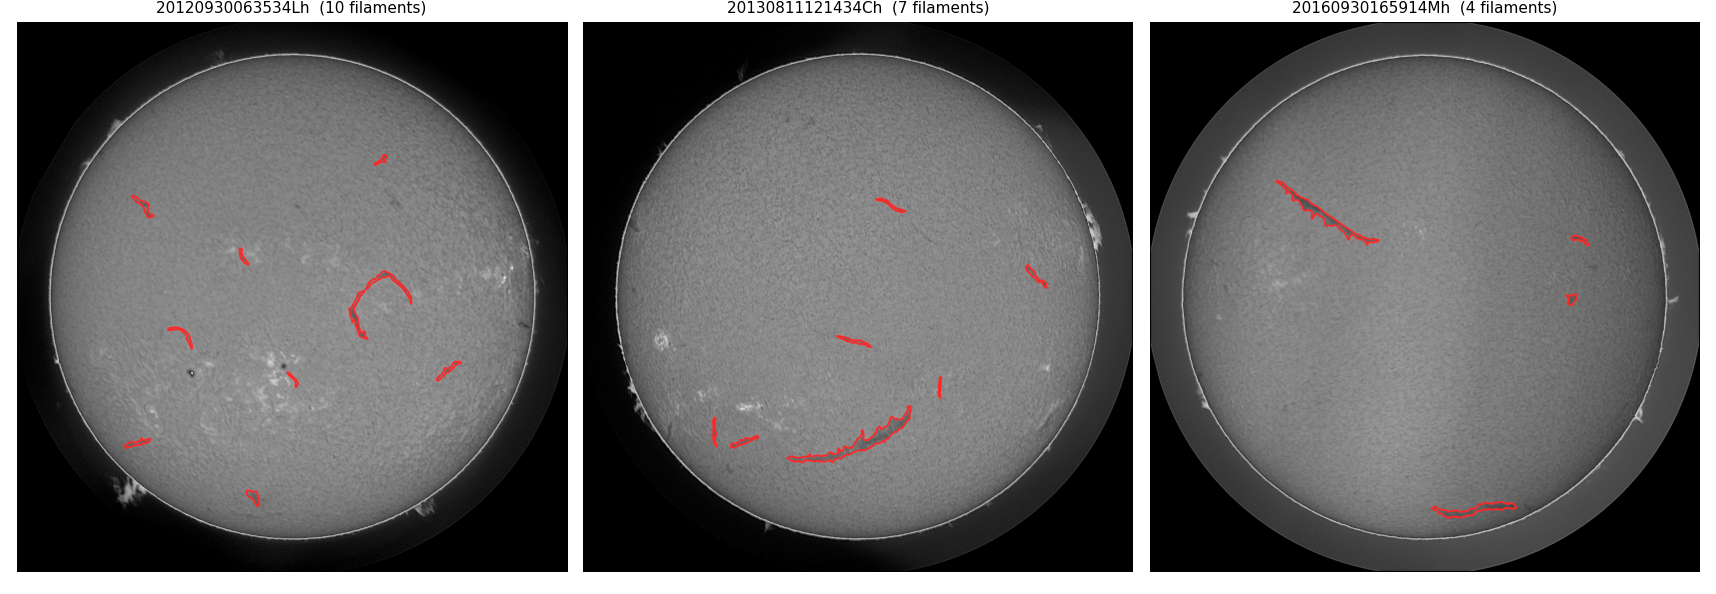

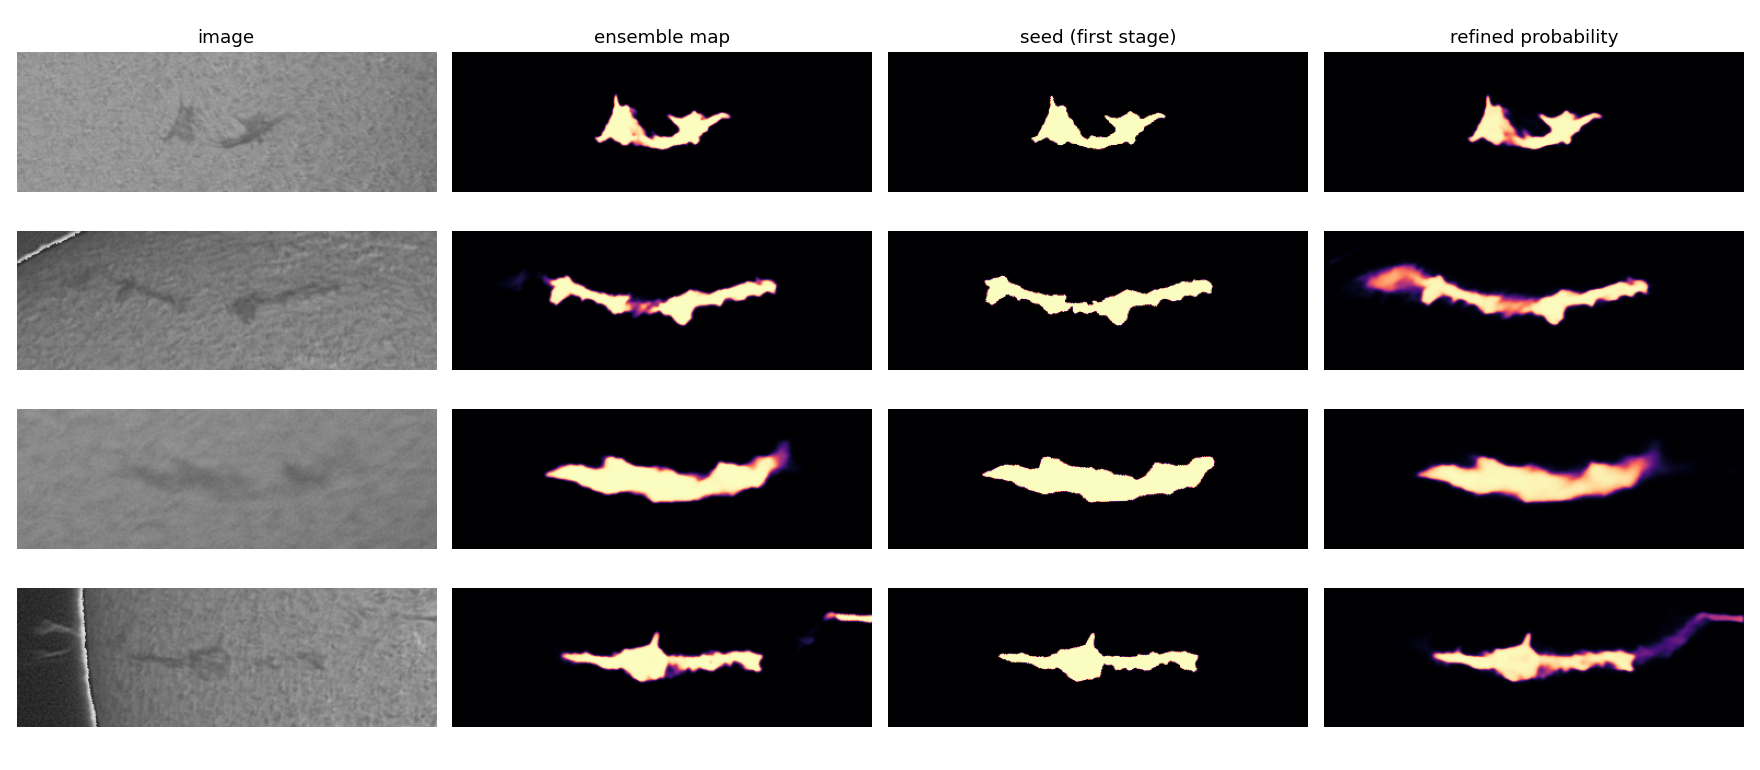

In [ ]:
from solfil import viz
from IPython.display import Image, display
R = viz.load('/tmp/solfil', 'submission.csv')
lam_best = json.load(open(f'{WD}/stage1/model.json'))['lam_best']
cnt = R['sub'].stem.value_counts()
os.makedirs('figures', exist_ok=True)
viz.stages_figure(R, cnt.index[len(cnt) // 2], lam_best, 'figures/stages.png')
viz.examples_figure(R, list(cnt.index[[len(cnt) // 4, len(cnt) // 2 + 1, 3 * len(cnt) // 4]]), 'figures/examples.png')
viz.refine_figure(R, np.load('/tmp/solfil/refined.npy'), 'figures/refine.png')
for f in ('stages', 'examples', 'refine'):
    display(Image(f'figures/{f}.png'))

## Checks: no overlapping instances; comparison with the submission of the training notebook (stage 16)

In [ ]:
if os.path.exists('/kaggle/input'):    # comparison with the Kaggle training notebooks (their outputs exist only on Kaggle)
    import subprocess, torch
    def find(slug, name):
        c = [p for p in glob.glob(f'/kaggle/input/**/{name}', recursive=True) if f'/{slug}/' in p]
        return c[0]
    import numpy as np, pandas as pd
    from pycocotools import mask as mu
    bad = 0
    for s, g in sub.groupby(sub.filament_id.str.rsplit('_', n=1).str[0]):
        rs = [dict(size=[2048, 2048], counts=c.encode()) for c in g.segmentation_rle]
        if len(rs) > 1:
            ov = np.array(mu.iou(rs, rs, [0] * len(rs))); np.fill_diagonal(ov, 0); bad += int(ov.max() > 0)
    print('images with overlapping instances', bad)
    ref = pd.read_csv(find('filament-s16-rescore-final', 'submission.csv'))
    same = len(set(ref.segmentation_rle) & set(sub.segmentation_rle))
    print('training-notebook submission', ref.shape, 'this notebook', sub.shape, 'identical masks', same, flush=True)
    ra = {r.filament_id.rsplit('_', 1)[0]: [] for r in ref.itertuples()}
    for r in ref.itertuples():
        ra[r.filament_id.rsplit('_', 1)[0]].append(dict(size=[2048, 2048], counts=r.segmentation_rle.encode()))
    best = []
    for r in sub.itertuples():
        g = ra.get(r.filament_id.rsplit('_', 1)[0], [])
        best.append(float(np.max(mu.iou([dict(size=[2048, 2048], counts=r.segmentation_rle.encode())], g, [0] * len(g)))) if g else 0.)
    best = np.array(best)
    print('best IoU of each instance against the training-notebook submission: mean', round(float(best.mean()), 4), '>0.99', round(float((best > .99).mean()), 4),
          '>0.5', round(float((best > .5).mean()), 4), flush=True)
    # stage 1 of this notebook against the test side of the training notebook of stage 14 (maps from the fp32 training runs)
    tc = pickle.load(open(find('filament-s14-pool-quality-final', 'test_candidates_q.pkl'), 'rb'))
    st1 = pickle.load(open('/tmp/solfil/stage1.pkl', 'rb'))
    n_same = n_all = 0; qa, qb = [], []
    for s, lst in tc.items():
        mine = st1['cands'].get(s, {})
        n_all += len(lst)
        for c, q in lst:
            if c in mine:
                n_same += 1
    sel_same = np.mean([[c for c, _ in st1['sel'].get(s, [])] == [c for c, _ in v] for s, v in pickle.load(open(find('filament-s14-pool-quality-final', 'selected_v43.pkl'), 'rb'))['sel'][json.load(open(f'{WD}/stage1/model.json'))['variant']]['test'].items()])
    print('stage-14 test candidates reproduced exactly', n_same, '/', n_all, '| images with the identical first-stage selection', round(float(sel_same), 3), flush=True)
    import platform, cv2, lightgbm, sklearn, scipy, torchvision, segmentation_models_pytorch as smp, pycocotools, timm
    print('versions', dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__, smp=smp.__version__,
                           timm=timm.__version__, numpy=np.__version__, pandas=pd.__version__, opencv=cv2.__version__, lightgbm=lightgbm.__version__,
                           scikit_learn=sklearn.__version__, scipy=scipy.__version__), flush=True)
    subprocess.run('pip freeze > /kaggle/working/pip_freeze.txt', shell=True)
    shutil.copy('/tmp/solfil/gpu0.log', '/kaggle/working/gpu0.log') if os.path.exists('/tmp/solfil/gpu0.log') else None
    shutil.copy('/tmp/solfil/gpu1.log', '/kaggle/working/gpu1.log') if os.path.exists('/tmp/solfil/gpu1.log') else None
    print(sorted(os.listdir('/kaggle/working')))

images with overlapping instances 0
training-notebook submission (1244, 2) this notebook (1244, 2) identical masks 482
best IoU of each instance against the training-notebook submission: mean 0.9898 >0.99 0.8907 >0.5 0.9936
stage-14 test candidates reproduced exactly 21298 / 28448 | images with the identical first-stage selection 0.089
versions {'python': '3.13.16', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'smp': '0.3.4', 'timm': '0.9.7', 'numpy': '2.1.3', 'pandas': '2.3.3', 'opencv': '4.14.0', 'lightgbm': '4.6.0', 'scikit_learn': '1.6.1', 'scipy': '1.16.3'}
['__notebook__.ipynb', 'figures', 'gpu0.log', 'gpu1.log', 'pip_freeze.txt', 'solfil', 'submission.csv', 'submission_quality.csv', 'weights']


## Out-of-fold evaluation (705 training images, 5 folds)

Computed by the training notebook of stage 16 (`training/s16_rescore_submit.py`) with the same matching as the competition
metric: every annotator record of an image is scored separately against all predictions of the image (IoU > 0.5).
`results/` holds the per-annotation, per-prediction and per-record tables behind these numbers.


{
 "all": {
  "PQ": 0.46193532778516244,
  "SQ": 0.6819335511762491,
  "RQ": 0.677390527256479,
  "TP": 5306,
  "FP": 2161,
  "FN": 2893,
  "matched_iou_q": [
   0.5597,
   0.6162,
   0.6878,
   0.7489,
   0.7925
  ],
  "matched_dice_mean": 0.8076863614341556,
  "one_to_many": 0.02305159165751921,
  "many_to_one": 0.02370747388159657
 },
 "K1": {
  "PQ": 0.4662005905231686,
  "SQ": 0.6873082132513147,
  "RQ": 0.6782991699136033,
  "TP": 2002,
  "FP": 695,
  "FN": 1204,
  "matched_iou_q": [
   0.5641,
   0.6224,
   0.6912,
   0.7546,
   0.8003
  ],
  "matched_dice_mean": 0.8114277068608078,
  "one_to_many": 0.022145976294447912,
  "many_to_one": 0.027067111605487578
 },
 "K2+": {
  "PQ": 0.45935642315108993,
  "SQ": 0.6786768703426288,
  "RQ": 0.6768411348970603,
  "TP": 3304,
  "FP": 1466,
  "FN": 1689,
  "matched_iou_q": [
   0.5574,
   0.6114,
   0.6844,
   0.7456,
   0.7871
  ],
  "matched_dice_mean": 0.8054193597561417,
  "one_to_many": 0.02363308632084919,
  "many_to_one": 0.02180

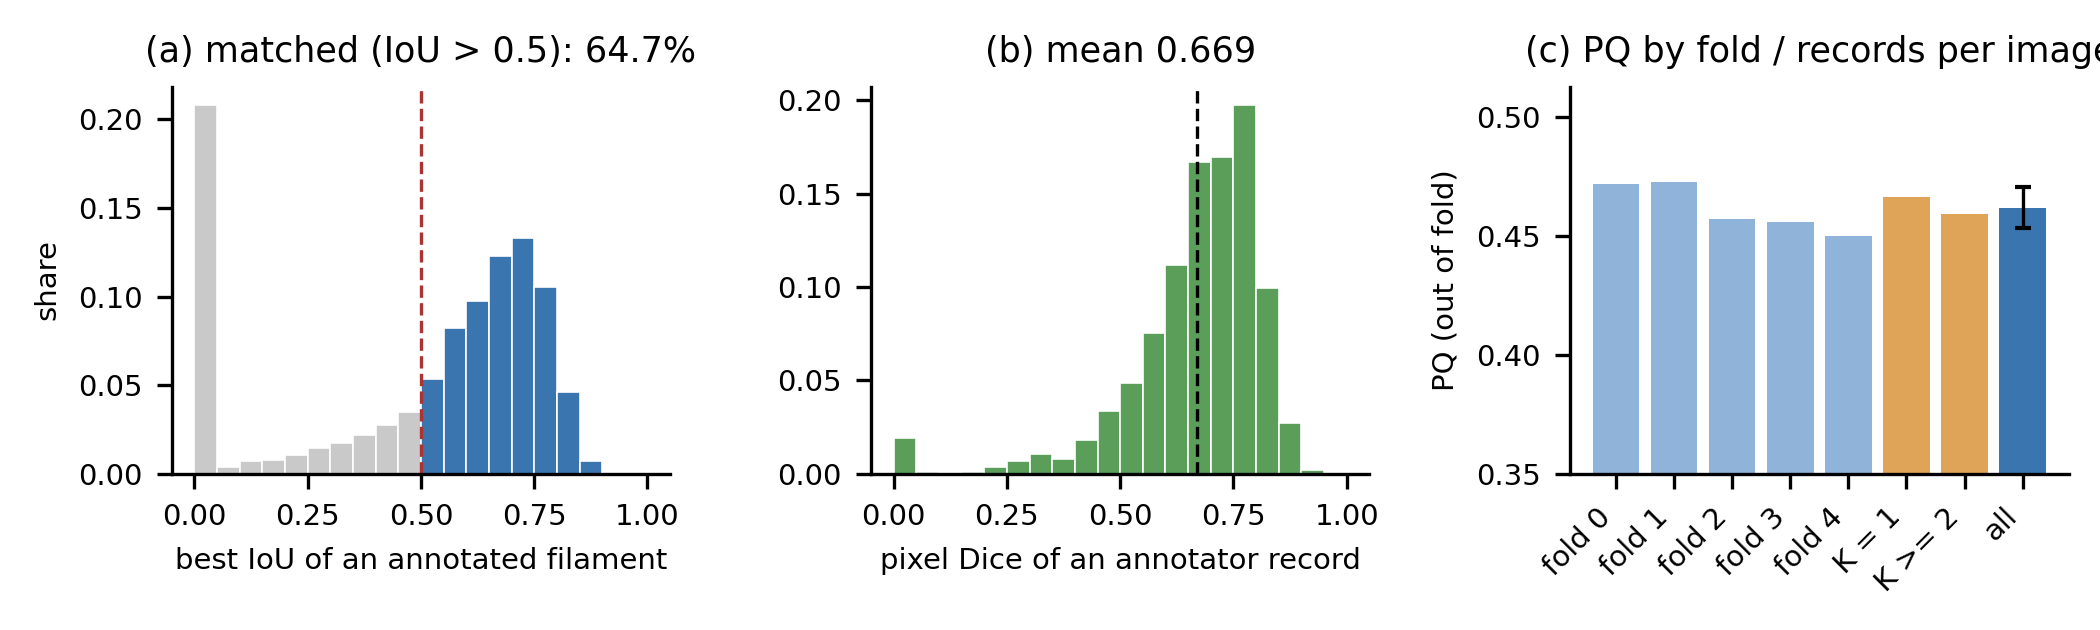

In [ ]:
EV = json.load(open('results/eval_oof.json'))
print(json.dumps({k: EV[k] for k in ('all', 'K1', 'K2+', 'pixel_dice_per_record', 'PQ_bootstrap_95', 'PQ_by_fold', 'instances_per_image')}, indent=1))
from IPython.display import Image, display
display(Image('report/figures/eval.png'))